# Fase 2 — Cobertura y Brecha Mediática (UNISON)

Este notebook genera los gráficos de la Fase 2 a partir de las métricas persistidas por `src/data/fase2_cobertura_brecha.py`. El análisis usa las menciones full-text (título + cuerpo) y el corpus completo de 37,882 notas.

1. Frecuencia absoluta por programa.
2. Brecha Pregrado vs. Posgrado.
3. Evolución temporal normalizada por volumen.
4. Índice de olvido.
5. Concentración.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

PROCESADO = Path('../data/processed').resolve()

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 120)

## 1. Tabla resumen del Punto de Control 2

Programa | Nivel | Grupo | Total de Menciones | % de Cobertura Institucional | % del Subconjunto | Categoría | Tópico Principal Asociado

In [2]:
resumen = pd.read_parquet(PROCESADO / 'resumen_pc2.parquet')
cobertura = pd.read_parquet(PROCESADO / 'cobertura_programas.parquet')
brecha = pd.read_parquet(PROCESADO / 'brecha_nivel.parquet')
anual = pd.read_parquet(PROCESADO / 'cobertura_anual.parquet')
evolucion = pd.read_parquet(PROCESADO / 'evolucion_nivel.parquet')
olvido = pd.read_parquet(PROCESADO / 'olvido_mediatico.parquet')
concentracion = pd.read_parquet(PROCESADO / 'concentracion.parquet')

display(resumen.head(20))
display(brecha)

,Ranking,Programa,Nivel,Grupo,Total Menciones,% Cobertura Institucional,% del Subconjunto,Categoria,Cuartil,Índice de Olvido,Primer Año,Último Año,Años Activo,Tópico Principal Asociado,Peso Tópico Principal (%),Tópico 2 Asociado,Peso Tópico 2 (%),Tópico 3 Asociado,Peso Tópico 3 (%),Categoría Principal,% Categoría Principal,Categoría 2,% Categoría 2,Categoría 3,% Categoría 3
0,1,Ingeniería Industrial y de Sistemas,Ingeniería,Pregrado,1504,3.970,9.78,Alta cobertura,Q4,0.000,2003,2026,24,Ingeniería y tecnología,19.00,Unidades regionales,9.91,Eventos académicos,9.89,Sustentabilidad y medio ambiente,11.30,Tecnología e innovación,10.97,Vinculación y sector productivo,10.57
1,2,Licenciatura en Derecho,Licenciatura,Pregrado,1112,2.935,7.23,Alta cobertura,Q4,0.261,2003,2026,24,Derecho y ciencias sociales,23.11,Unidades regionales,13.51,Vida estudiantil y movilidad,9.67,Derecho y justicia,22.84,"Derechos, género e inclusión",8.72,Egresados y graduación,8.63
2,3,Licenciatura en Ciencias de la Comunicación,Licenciatura,Pregrado,1025,2.706,6.66,Alta cobertura,Q4,0.318,2003,2026,24,Derecho y ciencias sociales,20.29,Vida estudiantil y movilidad,12.82,Eventos académicos,9.68,Divulgación y medios,21.27,Artes y cultura,10.44,Oferta educativa y docencia,10.44
3,4,Ingeniería Civil,Ingeniería,Pregrado,958,2.529,6.23,Alta cobertura,Q4,0.363,2003,2026,24,Ingeniería y tecnología,18.65,Gobierno universitario,11.58,Vida estudiantil y movilidad,10.01,Oferta educativa y docencia,9.92,Sustentabilidad y medio ambiente,9.19,Vinculación y sector productivo,8.25
4,5,Ingeniería Química,Ingeniería,Pregrado,818,2.159,5.32,Alta cobertura,Q4,0.456,2003,2026,24,Ingeniería y tecnología,25.68,Vida estudiantil y movilidad,11.10,Eventos académicos,10.18,Sustentabilidad y medio ambiente,18.09,Investigación y ciencia,10.64,Eventos académicos y congresos,7.33
5,6,Posgrado en Ciencias y Tecnología de Alimentos,Posgrado,Posgrado,752,1.985,4.89,Alta cobertura,Q4,0.500,2003,2026,24,Alimentos y nutrición,49.70,Eventos académicos,7.77,Gobierno universitario,5.62,Investigación y ciencia,21.01,Agropecuario y alimentos,9.97,Salud y medicina,9.71
6,7,Licenciatura en Psicología,Licenciatura,Pregrado,716,1.890,4.65,Alta cobertura,Q4,0.524,2003,2026,24,Derecho y ciencias sociales,19.42,Sociedad y vida universitaria,9.28,Vida estudiantil y movilidad,8.72,Salud y medicina,15.64,Oferta educativa y docencia,15.36,"Derechos, género e inclusión",7.96
7,8,Licenciatura en Música,Licenciatura,Pregrado,712,1.880,4.63,Alta cobertura,Q4,0.527,2004,2026,23,"Artes, música y danza",51.32,Egreso y graduación,6.25,Vida estudiantil y movilidad,5.90,Artes y cultura,66.01,Egresados y graduación,4.63,Reconocimientos y premios,3.23
8,9,Licenciatura en Artes,Licenciatura,Pregrado,688,1.816,4.47,Alta cobertura,Q4,0.543,2003,2026,24,"Artes, música y danza",57.25,Vida estudiantil y movilidad,7.58,Gobierno universitario,6.25,Artes y cultura,72.53,Eventos académicos y congresos,2.76,Reconocimientos y premios,2.62
9,10,Licenciatura en Medicina,Licenciatura,Pregrado,613,1.618,3.98,Alta cobertura,Q4,0.592,2003,2026,24,Salud y enfermería,19.39,Gobierno universitario,12.99,Vida estudiantil y movilidad,8.95,Salud y medicina,48.29,Admisión e ingreso,7.34,Oferta educativa y docencia,6.20


,Grupo,Notas,Menciones,Programas,Programas_Activos,Menciones_por_Programa,Promedio_Notas_Catalogo,Mediana_Notas,Maximo_Notas,Promedio_Notas_Activos,% Menciones,% Cobertura institucional,% del catálogo,% Programas activos
0,Pregrado,12633,17763,61,61,17763,291.20,205.0,1504,291.20,79.29,33.348,46.56,100.00
1,Posgrado,3889,4640,70,68,4640,66.29,26.0,752,68.24,20.71,10.266,53.44,97.14


## 2. Gráfico: barras horizontales de cobertura absoluta

Noticias por programa ordenadas de mayor a menor visibilidad.

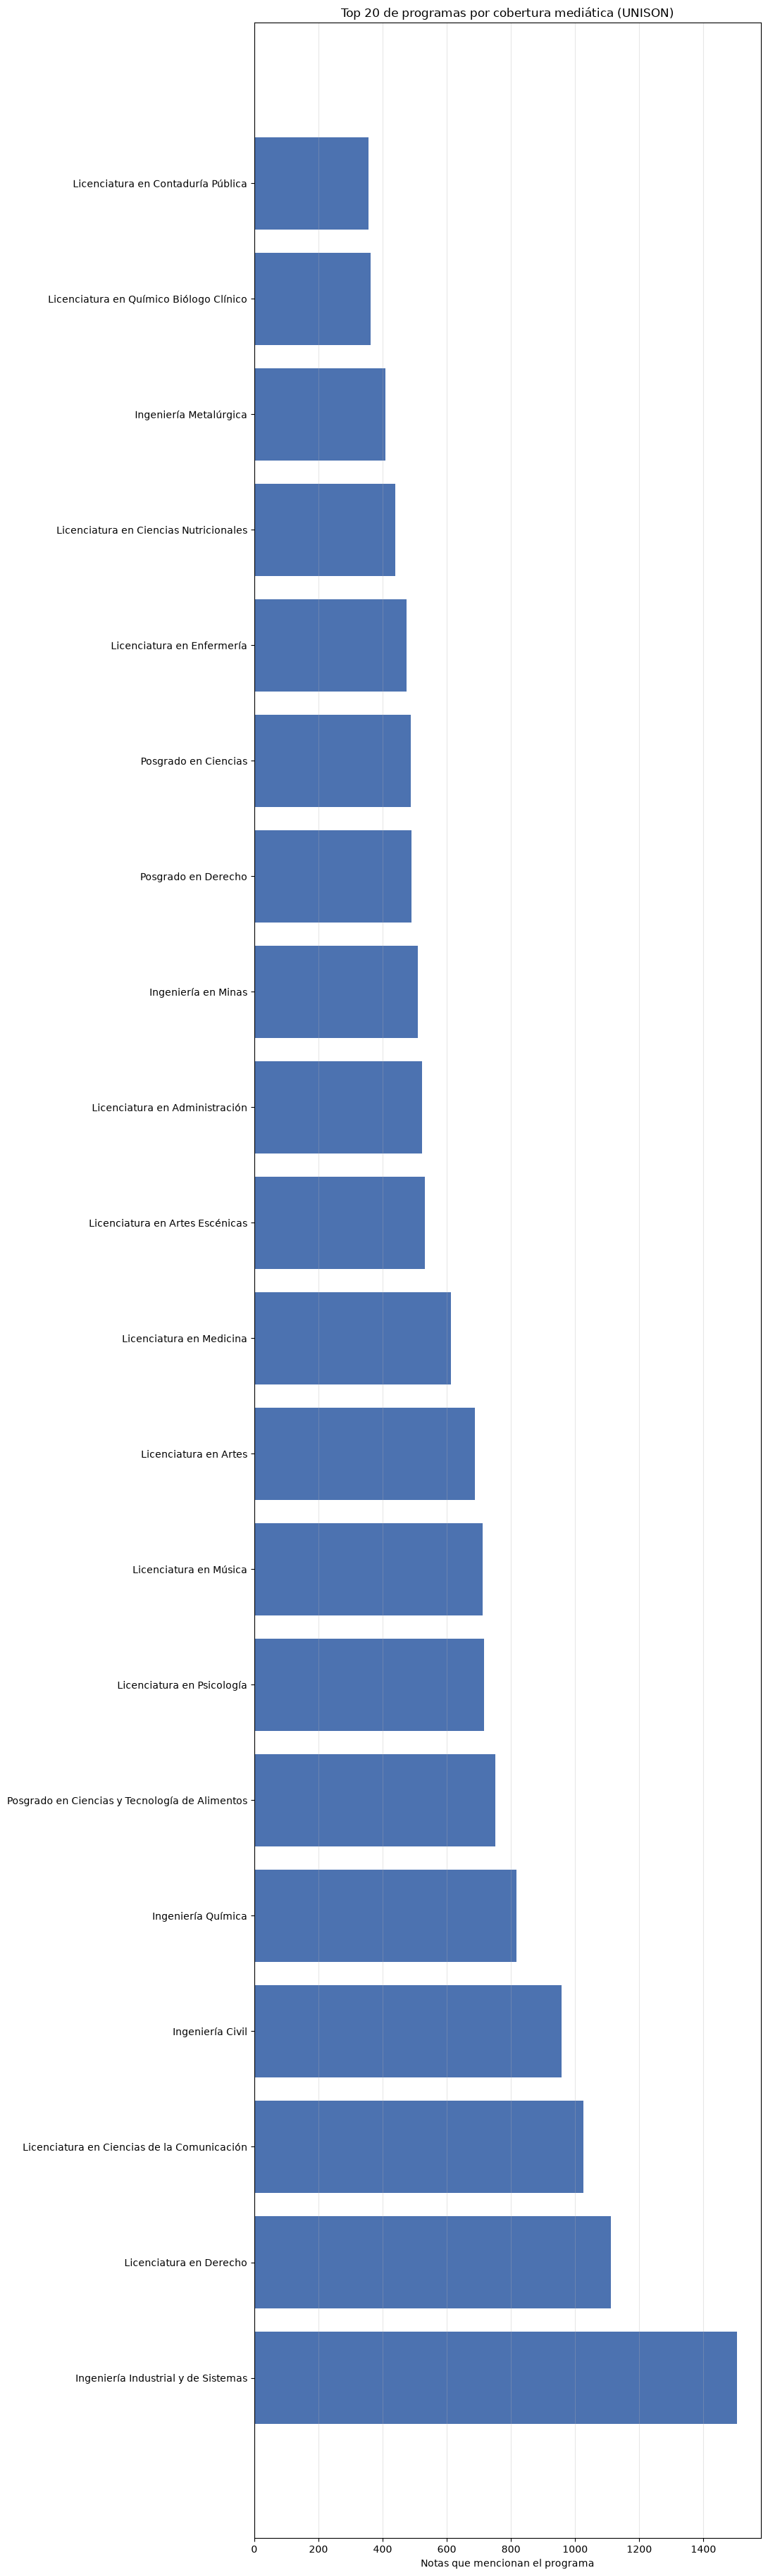

In [3]:
fig, ax = plt.subplots(figsize=(11, max(6, len(cobertura) * 0.28)))
top = cobertura.head(20).sort_values('Notas', ascending=True)
ax.barh(top['Programa'], top['Notas'], color='#4c72b0')
ax.invert_yaxis()
ax.set_xlabel('Notas que mencionan el programa')
ax.set_title('Top 20 de programas por cobertura mediática (UNISON)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Gráfico: brecha Pregrado vs. Posgrado

Participación en el total de menciones por nivel académico.

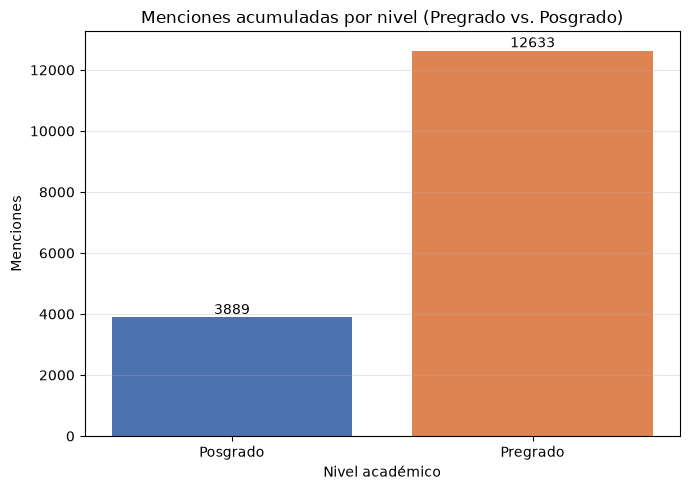

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
barras = brecha.sort_values('Notas', ascending=True)
ax.bar(barras['Grupo'], barras['Notas'], color=['#4c72b0', '#dd8452'])
ax.set_ylabel('Menciones')
ax.set_xlabel('Nivel académico')
ax.set_title('Menciones acumuladas por nivel (Pregrado vs. Posgrado)')
ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(barras['Notas']):
    ax.text(i, v, f'{v:.0f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## 4. Gráfico: mapa de calor programa × año

Menciones por programa en cada año (solo años completos).

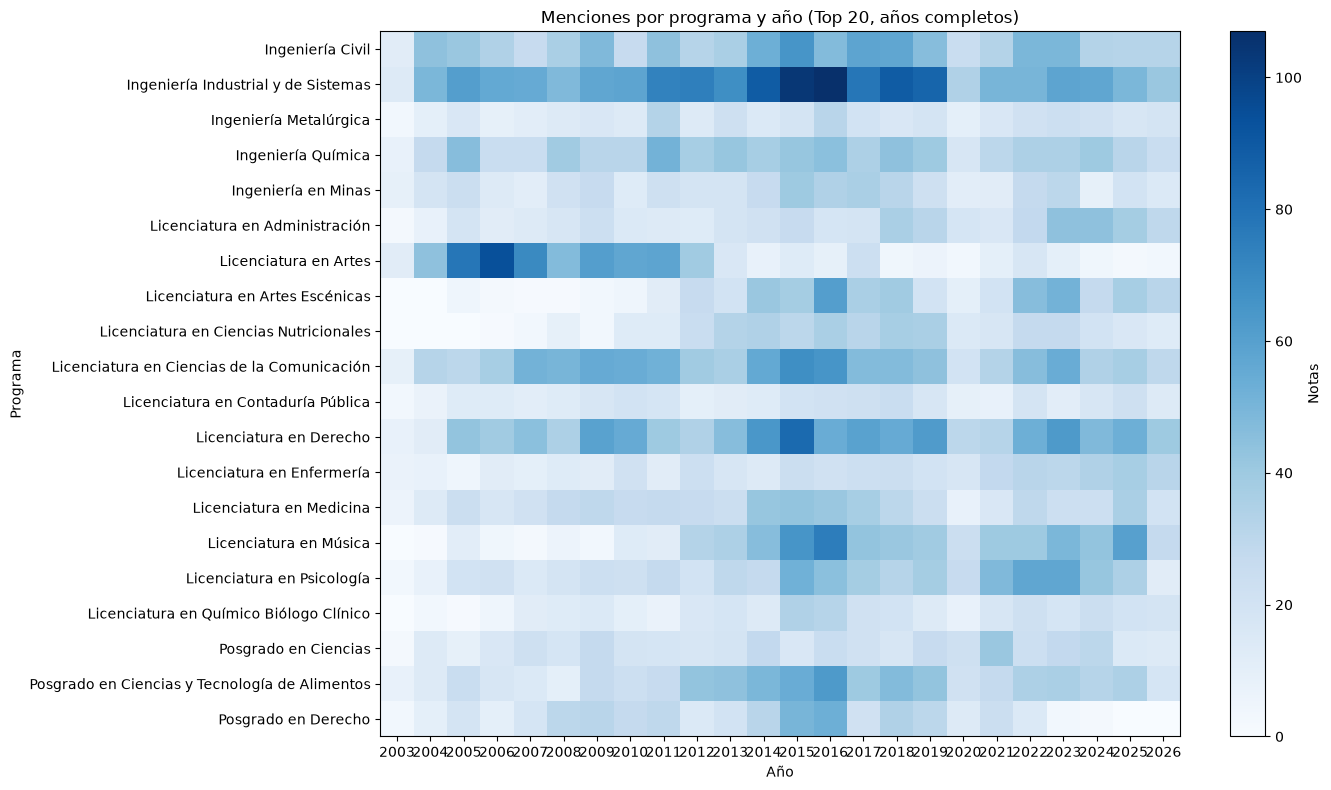

In [5]:
top_programas = cobertura.head(20)['Programa'].tolist()
sub = anual[anual['Programa'].isin(top_programas)].copy()
pivot = sub.pivot(index='Programa', columns='Año', values='Notas').fillna(0)
fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(pivot.values, aspect='auto', cmap='Blues')
ax.set_xticks(range(len(pivot.columns)), [str(c) for c in pivot.columns])
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_xlabel('Año')
ax.set_ylabel('Programa')
ax.set_title('Menciones por programa y año (Top 20, años completos)')
fig.colorbar(im, ax=ax, label='Notas')
plt.tight_layout()
plt.show()

## 5. Gráfico: evolución temporal normalizada

Menciones por 1,000 notas publicadas (Pregrado vs. Posgrado).

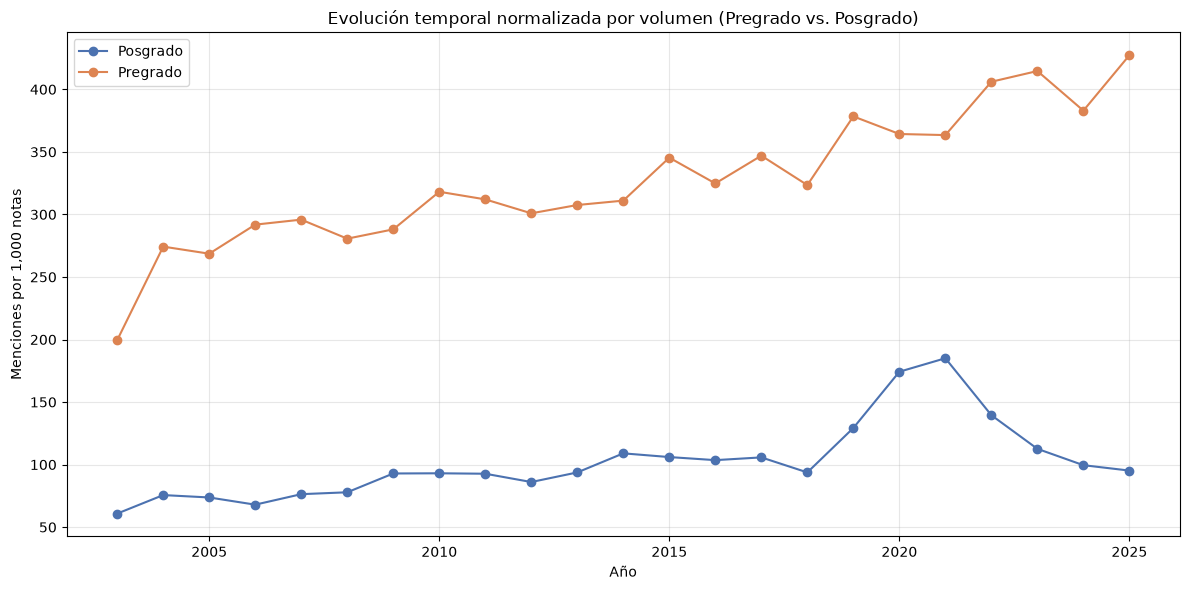

In [6]:
ev = evolucion[evolucion['Periodo_Tipo'] == 'Año'].copy()
ev = ev[~ev['Es_Periodo_Parcial']]
tabla = ev.pivot(index='Periodo', columns='Grupo', values='Notas por 1000').fillna(0)
tabla = tabla.sort_index()
fig, ax = plt.subplots(figsize=(12, 6))
for grupo, color in zip(tabla.columns, ['#4c72b0', '#dd8452']):
    ax.plot(tabla.index.astype(int), tabla[grupo], marker='o', label=grupo, color=color)
ax.set_xlabel('Año')
ax.set_ylabel('Menciones por 1,000 notas')
ax.set_title('Evolución temporal normalizada por volumen (Pregrado vs. Posgrado)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Gráfico: programas olvidados

Noticias acumuladas en el cuartil inferior del catálogo (incluye menciones únicas).

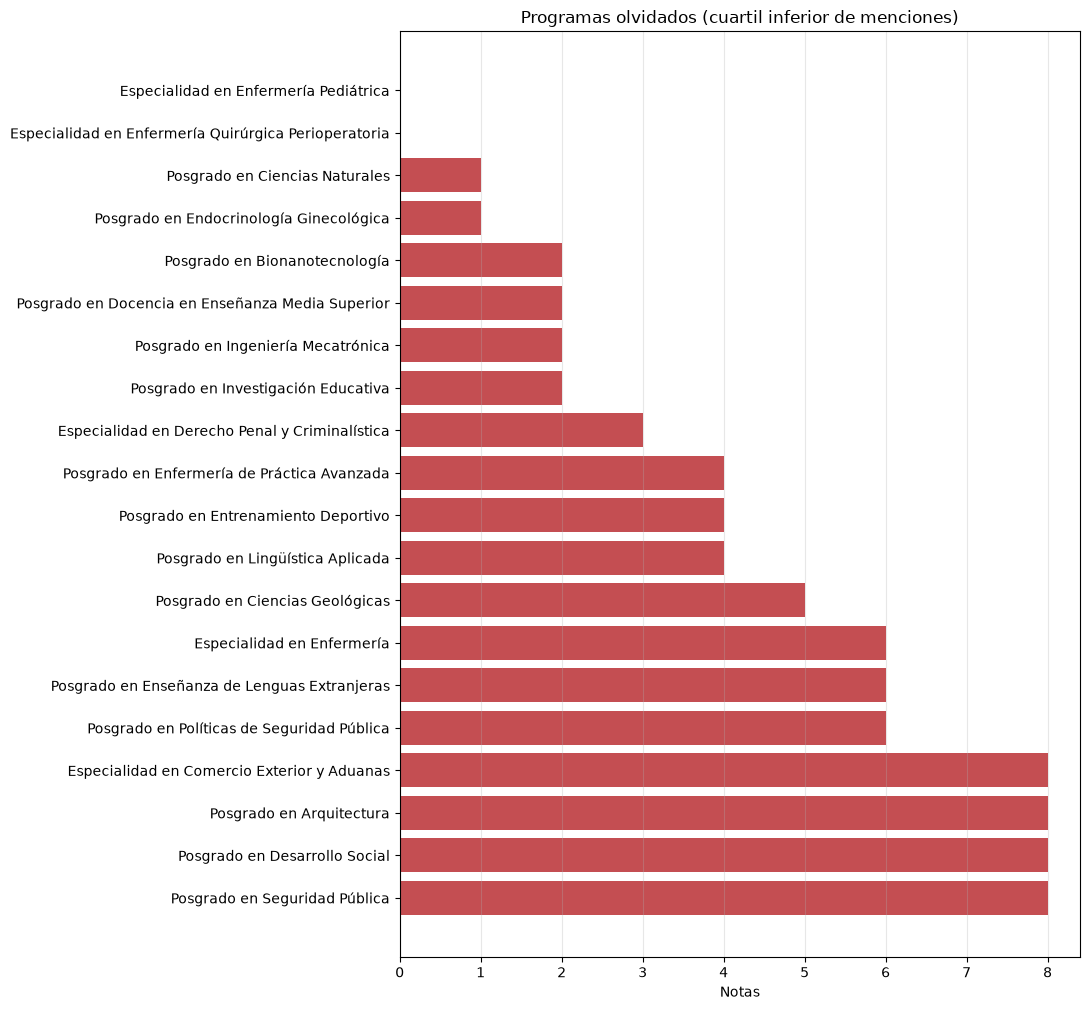

In [7]:
fig, ax = plt.subplots(figsize=(11, max(5, len(olvido) * 0.3)))
base = olvido.sort_values('Notas', ascending=True).head(20)
ax.barh(base['Programa'], base['Notas'], color='#c44e52')
ax.invert_yaxis()
ax.set_xlabel('Notas')
ax.set_title('Programas olvidados (cuartil inferior de menciones)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Gráfico: concentración

Participación del top-k de menciones, HHI y Gini.

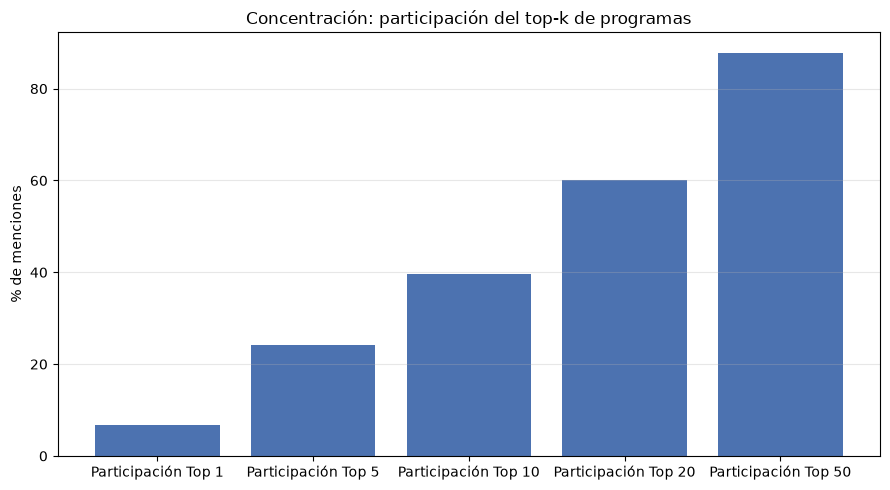

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
topk = concentracion[concentracion['Metrica'].str.startswith('Participación')]
ax.bar(topk['Metrica'], topk['Valor'], color='#4c72b0')
ax.set_ylabel('% de menciones')
ax.set_title('Concentración: participación del top-k de programas')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()